# PROYECTO (Trabajo Práctico) 1a Conv

**Asignatura:** Algoritmos de Optimización

**Nombre y Apellidos:** Lucas Ivan Tamara Trejo

**Url del repositorio GitHub:** https://github.com/lucastamaraucv/PROYECTO-AG

**Problemas a resolver:**
1. Sesiones de doblaje
2. Organizar los horarios de partidos de La Liga
3. Combinar cifras y operaciones

**Entrega:**
- Fecha límite (1ª convocatoria): 31/07/2026 23:59
- Formato: Notebook exportado a PDF con el resultado de ejecución de todas las celdas + archivo `.ipynb` + enlace al repositorio de GitHub (arriba)

(\*) La respuesta es obligatoria

## Índice

1. **Problema 1** — Sesiones de doblaje *(minimizar coste de desplazamiento de actores)*
2. **Problema 2** — Horarios de La Liga *(maximizar audiencia de la jornada)*
3. **Problema 3** — Combinar cifras y operaciones *(hallar valores máximo/mínimo/alcanzables)*

Cada problema se desarrolla en 3 bloques:
- **Bloque 1 — Modelado**: combinatoria, estructura de datos, función objetivo.
- **Bloque 2 — Algoritmos**: fuerza bruta y algoritmo mejorado, con sus complejidades.
- **Bloque 3 — Aplicación**: datos de prueba, referencias, líneas futuras.

**Evaluación:** 13 preguntas por problema (6 obligatorias, 7 opcionales) + 1 punto de presentación.

---
---
# PROBLEMA 1 — Sesiones de doblaje

## Descripción del problema

Se precisa coordinar el doblaje de una película. Los actores del doblaje deben coincidir en las tomas en las que sus personajes aparecen juntos en las diferentes tomas. Los actores de doblaje cobran todos la misma cantidad por cada día que deben desplazarse hasta el estudio de grabación, independientemente del número de tomas que se graben. No es posible grabar más de 6 tomas por día. El objetivo es planificar las sesiones por día de manera que el gasto por los servicios de los actores de doblaje sea el menor posible.

**Datos:**
- Número de actores: 10
- Número de tomas: 30
- Matriz Actores/Tomas: se consume directamente desde el Google Sheet del enunciado (https://docs.google.com/spreadsheets/d/1Ipn6IrbQP4ax8zOnivdBIw2lN0JISkJG4fXndYd27U0/edit?gid=0#gid=0), sin necesidad de descargarlo a disco (1 = el actor participa en la toma, 0 = no participa)

## Carga de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def fmt_dec(x, decimales=2):
    """Formatea un número decimal con coma (convención de Perú), sin separador de miles."""
    return f"{x:.{decimales}f}".replace(".", ",")

def print_banner(texto):
    """Imprime el texto en una caja con bordes Unicode, para que resalte en la consola/PDF."""
    ancho = len(texto) + 2
    print("┌" + "─" * ancho + "┐")
    print("│ " + texto + " │")
    print("└" + "─" * ancho + "┘")


# Se consume directamente desde el Google Sheet del enunciado (sin descargar CSV a disco):
# el mismo Sheet exportado en formato CSV vía su URL de exportación.
SHEET_ID = "1Ipn6IrbQP4ax8zOnivdBIw2lN0JISkJG4fXndYd27U0"
GID = "0"
url = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv&gid={GID}"

df = pd.read_csv(url, skiprows=1, index_col=0)
df = df.drop(columns=[c for c in df.columns if 'Unnamed' in c or c == 'Total'], errors='ignore')
df = df.dropna(how='all')
df = df[pd.to_numeric(df.index, errors='coerce').notna()]  # descarta la fila "TOTAL" final
df.index = df.index.astype(int)
df.columns = [int(c) for c in df.columns]
df.head()

,1,2,3,4,5,6,7,8,9,10
Toma,,,,,,,,,,
1,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
5,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


## Bloque 1 — Modelado del problema

> 📋 **Qué pide este bloque en conjunto:** antes de programar nada, exige entender el tamaño del espacio de soluciones (con y sin restricciones), decidir cómo representar los datos, y formalizar matemáticamente qué se optimiza y en qué sentido (min/max). Es la base sobre la que se apoyan los algoritmos del Bloque 2.

### 1.1 (\*) ¿Cuántas posibilidades hay sin tener en cuenta las restricciones?
### 1.2 ¿Cuántas posibilidades hay teniendo en cuenta todas las restricciones?

> 📋 **Qué pide:**
> - **1.1 (obligatoria):** conteo combinatorio puro. Pide calcular de cuántas formas distintas se pueden agrupar las 30 tomas en días de grabación, sin aplicar el límite de 6 tomas/día ni ninguna otra condición. Se espera una fórmula (basada en particiones de un conjunto) justificada en texto, y opcionalmente su cálculo en Python.
> - **1.2 (opcional):** el mismo conteo, pero ahora limitando cada grupo (día) a un máximo de 6 tomas. Pide identificar cuántas particiones válidas del conjunto de 30 tomas existen bajo esa restricción de tamaño.

**Respuesta:**

**1.1 — Sin restricciones:** la respuesta es B(30) = 846749014511809332450147 (~8,47×10²³) formas de agrupar las 30 tomas en días.

**1.2 — Con restricciones:** la respuesta es R(30) = 726391948970868949621309 formas, aplicando el límite real de máximo 6 tomas por día.

Ambos números salen de la misma recurrencia, construida sobre **combinaciones C(n,k)** (ya vistas en el curso): agrupar las 30 tomas en días es un problema de contar particiones de un conjunto — repartir 30 elementos distinguibles en un número no fijo de grupos no vacíos, sin importar el orden entre grupos. Se fija el bloque que contiene a una toma de referencia (de tamaño i, elegida entre las n-1 restantes con C(n-1,i-1)) y se particiona recursivamente el resto: R(n,k) = Σ_{i=1}^{min(n,k)} C(n-1,i-1)·R(n-i,k), con R(0,k)=1. Sin límite de bloque (k=30) da B(30); con el límite real (k=6) da R(30).

El punto clave es que el caso sin restricciones coincide con lo que en la literatura matemática se llama número de Bell — ese nombre no aparece en el material del curso, pero la recurrencia que lo calcula está armada enteramente con combinaciones + recursión, no con una técnica externa. Ambos resultados son números astronómicos que ya anticipan que la fuerza bruta pura sobre las 30 tomas completas es inviable, justificando la necesidad de un algoritmo mejorado (Bloque 2).

In [2]:
from math import comb
from functools import lru_cache

n_tomas = len(df)      # 30
max_por_dia = 6

# 1.1/1.2: agrupar las 30 tomas en días es un problema de contar PARTICIONES
# de un conjunto (grupos no vacíos, sin importar el orden entre grupos). Se
# resuelve con una única recurrencia construida enteramente sobre
# COMBINACIONES C(n,k) (ya vistas en el curso): para contar las particiones
# de n elementos, se fija el bloque que contiene a una toma de referencia
# (de tamaño i, elegida entre las n-1 restantes con C(n-1,i-1)) y se
# particiona recursivamente el resto. La misma función responde ambas
# preguntas, cambiando solo el límite de tamaño de bloque k:
#   - sin límite (k=n): el resultado coincide con lo que en la literatura
#     matemática se llama "número de Bell" B(n) (el nombre no aparece en
#     el material del curso, pero la recurrencia sí está armada 100% con
#     combinaciones + recursión).
#   - con límite k=6 (la restricción real del problema): da el conteo
#     acotado R(n).
@lru_cache(maxsize=None)
def contar_particiones(n, k):
    """Nº de formas de agrupar n elementos en bloques no vacíos de tamaño <= k."""
    if n == 0:
        return 1
    total = 0
    for i in range(1, min(n, k) + 1):
        total += comb(n - 1, i - 1) * contar_particiones(n - i, k)
    return total

B_n = contar_particiones(n_tomas, n_tomas)      # sin límite de bloque -> número de Bell B(n)
R_n = contar_particiones(n_tomas, max_por_dia)  # con el límite real de 6 tomas/día

print_banner("PROBLEMA 1 | 1.1 y 1.2 - Combinatoria (posibilidades de agrupar tomas en días)")
B_n_exp = f"{B_n:.3e}".replace(".", ",")
R_n_exp = f"{R_n:.3e}".replace(".", ",")
print(f"1.1 Sin restricciones -> B({n_tomas}) = {B_n}  (~{B_n_exp})")
print(f"1.2 Con restricción (<= {max_por_dia} tomas/día) -> R({n_tomas}) = {R_n}  (~{R_n_exp})")

┌────────────────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 1 | 1.1 y 1.2 - Combinatoria (posibilidades de agrupar tomas en días) │
└────────────────────────────────────────────────────────────────────────────────┘
1.1 Sin restricciones -> B(30) = 846749014511809332450147  (~8,467e+23)
1.2 Con restricción (<= 6 tomas/día) -> R(30) = 726391948970868949621309  (~7,264e+23)


### 1.3 (\*) ¿Cuál es la estructura de datos que mejor se adapta al problema? Argumenta la respuesta
*(Es posible que hayas elegido una al principio y veas la necesidad de cambiar, argumenta)*

> 📋 **Qué pide:**
> No es una pregunta de cálculo sino de **diseño**. Pide decidir cómo representar el problema en memoria y justificarlo: la matriz binaria actor×toma tal cual llega en los datos, un conjunto de actores por toma (más eficiente para calcular coincidencias entre tomas), o un grafo donde los nodos son tomas y las aristas indican que comparten al menos un actor. Se espera argumentar ventajas/inconvenientes de la estructura elegida de cara al algoritmo que se implemente, y mencionar si hubo un cambio de estructura a lo largo del trabajo.

**Respuesta:**

La estructura de datos elegida es la máscara de bits (bitmask): cada toma se representa como un entero de 10 bits, uno por actor.

Se llega a esa elección en dos pasos: para cargar y explorar los datos, la matriz binaria actor×toma (DataFrame de pandas) es la más natural, porque refleja directamente el enunciado y es fácil de inspeccionar. Pero para el algoritmo esa matriz se traduce a bitmask, mucho más eficiente: calcular la unión de actores de un grupo de tomas es un simple OR a nivel de bits, y contar cuántos actores distintos participan es `bin(mask).count('1')`, en vez de recorrer y unir conjuntos elemento a elemento.

Este cambio (matriz → bitmask) es clave para que los algoritmos del Bloque 2 sean eficientes, ya que evalúan el coste de miles de agrupaciones candidatas.

In [3]:
print("▸ [Problema 1 | 1.3] Estructura de datos: ejemplo de bitmask")

# Cada toma -> máscara de bits (bitmask) de 10 bits, uno por actor.
tomas_bitmask = {
    toma: int(''.join(str(int(v)) for v in fila), 2)
    for toma, fila in df.iterrows()
}

toma_ejemplo = df.index[0]
print(f"Toma {toma_ejemplo}: actores = {list(df.columns[df.loc[toma_ejemplo] == 1])}")
print(f"Toma {toma_ejemplo}: bitmask = {bin(tomas_bitmask[toma_ejemplo])}")

▸ [Problema 1 | 1.3] Estructura de datos: ejemplo de bitmask
Toma 1: actores = [1, 2, 3, 4, 5]
Toma 1: bitmask = 0b1111100000


### 1.4 (\*) ¿Cuál es la función objetivo?
### 1.5 (\*) ¿Es un problema de maximización o minimización?

> 📋 **Qué pide:**
> - **Función objetivo:** formalizar matemáticamente qué se optimiza. Aquí, el coste total es la suma, para cada día de la planificación, del número de actores distintos que deben desplazarse ese día (cada actor cobra un día completo si trabaja, sin importar cuántas tomas grabe). Se espera una expresión del tipo `Coste = Σ_d (nº de actores distintos que participan en las tomas asignadas al día d)`, junto con la explicación en texto.
> - **Max o min:** respuesta directa y justificada — es un problema de **minimización** (minimizar el gasto en desplazamientos de actores).

**Respuesta:**

La función objetivo es Coste(P) = Σⱼ |A(Dⱼ)|, y es un problema de **minimización**: el enunciado pide explícitamente que el gasto en desplazamientos de actores sea el menor posible, no hay ningún valor que convenga maximizar.

Sea P = {D₁, ..., Dₘ} una partición de las 30 tomas en grupos (días), cada uno con |Dⱼ| ≤ 6. Para cada día Dⱼ, sea A(Dⱼ) el conjunto de actores distintos que participan en alguna toma de Dⱼ. El coste total es la suma, día a día, del número de actores que tuvieron que desplazarse ese día — cada actor cobra un día completo si trabaja, sin importar cuántas tomas grabe.

Se busca la partición P que minimiza Coste(P), sujeta a |Dⱼ| ≤ 6 para todo j.

In [4]:
print("▸ [Problema 1 | 1.4] Función objetivo: ejemplo de coste")

def coste_dia(dia, tomas_bitmask):
    """Nº de actores distintos (bits a 1) que participan en las tomas de un día."""
    mask = 0
    for t in dia:
        mask |= tomas_bitmask[t]
    return bin(mask).count('1')

def coste_particion(particion, tomas_bitmask):
    """particion: lista de días (cada día = lista de tomas). Devuelve el coste total."""
    return sum(coste_dia(dia, tomas_bitmask) for dia in particion)

# Ejemplo ilustrativo: coste de meter todas las tomas en un único día
# (no respeta el límite de 6, solo sirve para comprobar la función)
print("Coste de ejemplo (todas las tomas en un día):",
      coste_particion([list(df.index)], tomas_bitmask))

▸ [Problema 1 | 1.4] Función objetivo: ejemplo de coste
Coste de ejemplo (todas las tomas en un día): 10


## Bloque 2 — Diseño y análisis de algoritmos

> 📋 **Qué pide este bloque en conjunto:** primero resolver el problema "ingenuamente" (fuerza bruta) y medir su coste computacional; después proponer y justificar una alternativa más eficiente, midiendo también su complejidad; y por último preparar datos sintéticos para poder probar ambos algoritmos a distinta escala.

### 2.1 Diseña un algoritmo para resolver el problema por fuerza bruta

> 📋 **Qué pide:**
> Pide diseñar (y programar) un algoritmo de **búsqueda exhaustiva**: generar todas las particiones válidas de las 30 tomas en grupos de tamaño ≤6 (el espacio de soluciones descrito en 1.2), calcular el coste de cada partición según la función objetivo de 1.4, y quedarse con la de menor coste. Se espera el código Python correspondiente además de la explicación textual del enfoque.

**Respuesta:**

El algoritmo de fuerza bruta es un *backtracking*: genera todas las particiones válidas de las tomas en grupos de tamaño ≤6 (el espacio contado en 1.2) y calcula el coste de cada una con la función objetivo de 1.4, quedándose con la de menor coste.

Se fija la primera toma sin asignar y se prueban todos los posibles grupos (de tamaño 1 a 6) que la contengan junto con distintas combinaciones de otras tomas; para cada elección se repite el proceso recursivamente con las tomas restantes, generando así cada partición exactamente una vez. Se añade una poda simple: si el coste parcial ya iguala o supera el mejor coste encontrado hasta el momento, se abandona esa rama.

Dado que el número de particiones para n=30 es del orden de R(30) (1.2), este algoritmo no es viable sobre las 30 tomas completas — se demuestra aquí sobre un subconjunto reducido (las 8 primeras tomas) y se usa como referencia de optimalidad en el Bloque 3.

In [5]:
print("▸ [Problema 1 | 2.1] Fuerza bruta (backtracking)")

import itertools

def fuerza_bruta(tomas, tomas_bitmask, max_dia=6):
    """Explora TODAS las particiones válidas (bloques <= max_dia) y devuelve
    la de menor coste. Solo viable para pocas tomas (n pequeño)."""
    tomas = list(tomas)
    mejor_coste = [None]
    mejor_particion = [None]

    def backtrack(restantes, particion_actual, coste_actual):
        if not restantes:
            if mejor_coste[0] is None or coste_actual < mejor_coste[0]:
                mejor_coste[0] = coste_actual
                mejor_particion[0] = [list(d) for d in particion_actual]
            return
        if mejor_coste[0] is not None and coste_actual >= mejor_coste[0]:
            return  # poda: esta rama ya no puede mejorar la mejor solución conocida
        primera = restantes[0]
        resto = restantes[1:]
        for tam in range(1, min(max_dia, len(restantes)) + 1):
            for companeras in itertools.combinations(resto, tam - 1):
                dia = (primera,) + companeras
                coste_este_dia = coste_dia(dia, tomas_bitmask)
                nuevos_restantes = [t for t in resto if t not in companeras]
                backtrack(nuevos_restantes, particion_actual + [dia], coste_actual + coste_este_dia)

    backtrack(tomas, [], 0)
    return mejor_particion[0], mejor_coste[0]

# Demostración sobre un subconjunto pequeño (viabilidad computacional, ver 2.2)
subset_bruta = list(df.index[:8])
particion_opt, coste_opt = fuerza_bruta(subset_bruta, tomas_bitmask)
print(f"Fuerza bruta sobre {len(subset_bruta)} tomas -> coste óptimo = {coste_opt}")
print("Partición óptima:", particion_opt)

▸ [Problema 1 | 2.1] Fuerza bruta (backtracking)
Fuerza bruta sobre 8 tomas -> coste óptimo = 12
Partición óptima: [[1, 2], [3, 4, 5, 6, 7, 8]]


### 2.2 Calcula la complejidad del algoritmo por fuerza bruta

> 📋 **Qué pide:**
> Pide el análisis de complejidad (notación Big-O) del algoritmo de 2.1, apoyándose en el número de particiones calculado en 1.2. Al tratarse de una enumeración de particiones con restricción de tamaño, se espera un crecimiento exponencial/factorial en función del número de tomas, justificando cómo se llega a esa cota.

**Respuesta:**

La complejidad es T(n) = O(R(n) · n), superexponencial.

El número de particiones exploradas por la fuerza bruta es exactamente R(n) (el número de Bell acotado, calculado en 1.2), y cada partición completa requiere O(n) operaciones para sumar el coste de sus días. R(n) crece de forma superexponencial con n (ver la celda de código: para n pequeño es manejable, pero se dispara rápidamente). Para n=30, R(30) tiene más de 20 dígitos, por lo que T(30) es completamente inabordable en la práctica — de ahí la necesidad de un algoritmo mejorado (2.3).

┌─────────────────────────────────────────────────────┐
│ PROBLEMA 1 | 2.2 - Complejidad: crecimiento de R(n) │
└─────────────────────────────────────────────────────┘
n= 5 tomas -> R(n) = 52 particiones posibles
n= 6 tomas -> R(n) = 203 particiones posibles
n= 7 tomas -> R(n) = 876 particiones posibles
n= 8 tomas -> R(n) = 4131 particiones posibles
n= 9 tomas -> R(n) = 21065 particiones posibles
n=10 tomas -> R(n) = 115274 particiones posibles
n=11 tomas -> R(n) = 672673 particiones posibles
n=12 tomas -> R(n) = 4163743 particiones posibles
n=13 tomas -> R(n) = 27216840 particiones posibles
n=14 tomas -> R(n) = 187160429 particiones posibles


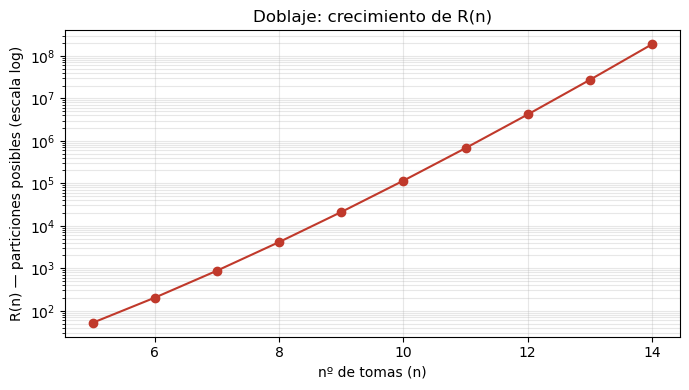

In [6]:
print_banner("PROBLEMA 1 | 2.2 - Complejidad: crecimiento de R(n)")

# Crecimiento de R(n) (nº de particiones con bloques <= 6) para ilustrar
# por qué la fuerza bruta deja de ser viable muy rápido
ns = list(range(5, 15))
valores_r = [contar_particiones(n, max_por_dia) for n in ns]
for n, v in zip(ns, valores_r):
    print(f"n={n:2d} tomas -> R(n) = {v} particiones posibles")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, valores_r, marker='o', color='#c0392b')
ax.set_yscale('log')
ax.set_xlabel('nº de tomas (n)')
ax.set_ylabel('R(n) — particiones posibles (escala log)')
ax.set_title('Doblaje: crecimiento de R(n)')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 (\*) Diseña un algoritmo que mejore la complejidad del algoritmo por fuerza bruta. Argumenta por qué crees que mejora el algoritmo por fuerza bruta

> 📋 **Qué pide:**
> Pide proponer un algoritmo alternativo que no explore todo el espacio de soluciones, usando alguna de las técnicas vistas en la asignatura (búsqueda aleatoria, búsqueda local, recocido simulado, colonia de hormigas, algoritmos genéticos) o un algoritmo voraz (greedy) que agrupe tomas priorizando las que comparten más actores. Además de implementarlo, se pide **argumentar** por qué mejora la complejidad frente a la fuerza bruta (qué parte del espacio de búsqueda deja de explorar y qué se sacrifica, si acaso, en optimalidad).

**Respuesta:**

El algoritmo mejorado es **voraz (greedy) + búsqueda local**, y evita la exploración exhaustiva de 2.1.

La construcción voraz recorre las tomas y asigna cada una al día ya abierto (con menos de 6 tomas) cuyo coste marginal sea menor; si ningún día abierto es adecuado o todos están llenos, se abre un día nuevo. La búsqueda local parte de esa solución voraz y prueba repetidamente movimientos de una toma de un día a otro, aceptando el cambio solo si reduce el coste total y respeta el límite de 6 tomas/día, hasta que ninguna mejora sea posible o se agote el número máximo de iteraciones.

Mejora la complejidad porque, a diferencia de la fuerza bruta (que explora las R(n) particiones completas), este algoritmo construye una única solución inicial en tiempo polinómico y la refina con un número acotado de movimientos locales, sin generar ni comparar todas las particiones posibles. Se sacrifica la garantía de optimalidad global a cambio de una complejidad drásticamente menor (ver 2.4).

In [7]:
print("▸ [Problema 1 | 2.3-2.4] Algoritmo mejorado: voraz + búsqueda local")

import random

def algoritmo_voraz(tomas, tomas_bitmask, max_dia=6):
    dias = []  # lista de días, cada día = lista de tomas
    for toma in tomas:
        mejor_dia = None
        mejor_incremento = None
        for dia in dias:
            if len(dia) < max_dia:
                incremento = coste_dia(dia + [toma], tomas_bitmask) - coste_dia(dia, tomas_bitmask)
                if mejor_incremento is None or incremento < mejor_incremento:
                    mejor_incremento = incremento
                    mejor_dia = dia
        if mejor_dia is not None:
            mejor_dia.append(toma)
        else:
            dias.append([toma])
    return dias

def busqueda_local(dias, tomas_bitmask, max_dia=6, max_iter=1000):
    # Dos tipos de movimiento: (a) MOVER una toma suelta a otro día con hueco
    # libre, (b) INTERCAMBIAR una toma de un día por una de otro (equivalente
    # al operador 2-opt de vecindad). El intercambio hace falta porque, cuando
    # los dos días ya están llenos (6 tomas), ningún "mover" es posible; sin
    # ese movimiento el algoritmo se queda atascado en un óptimo local peor
    # (verificado con los datos reales: solo con "mover" el coste queda en 38,
    # con el intercambio agregado baja a 30).
    dias = [list(d) for d in dias]
    mejor_coste = sum(coste_dia(d, tomas_bitmask) for d in dias)
    mejorado = True
    it = 0
    while mejorado and it < max_iter:
        mejorado = False
        it += 1
        for i, j in itertools.combinations(range(len(dias)), 2):
            # a) mover, en ambos sentidos
            for origen, destino in ((i, j), (j, i)):
                for toma in list(dias[origen]):
                    if len(dias[destino]) < max_dia:
                        dias[origen].remove(toma); dias[destino].append(toma)
                        nuevo_coste = sum(coste_dia(d, tomas_bitmask) for d in dias if d)
                        if nuevo_coste < mejor_coste:
                            mejor_coste, mejorado = nuevo_coste, True
                        else:
                            dias[destino].remove(toma); dias[origen].append(toma)
            # b) intercambiar una toma de i por una de j
            for toma_i in list(dias[i]):
                for toma_j in list(dias[j]):
                    if toma_i not in dias[i] or toma_j not in dias[j]:
                        continue
                    dias[i].remove(toma_i); dias[j].remove(toma_j)
                    dias[i].append(toma_j); dias[j].append(toma_i)
                    nuevo_coste = sum(coste_dia(d, tomas_bitmask) for d in dias if d)
                    if nuevo_coste < mejor_coste:
                        mejor_coste, mejorado = nuevo_coste, True
                    else:
                        dias[i].remove(toma_j); dias[j].remove(toma_i)
                        dias[i].append(toma_i); dias[j].append(toma_j)
    dias = [d for d in dias if d]
    return dias, mejor_coste

def algoritmo_mejorado(tomas, tomas_bitmask, max_dia=6, seed=42):
    tomas = list(tomas)
    random.Random(seed).shuffle(tomas)
    dias_iniciales = algoritmo_voraz(tomas, tomas_bitmask, max_dia)
    return busqueda_local(dias_iniciales, tomas_bitmask, max_dia)

# Comparación contra la fuerza bruta en el mismo subconjunto de 2.1
dias_mejorado, coste_mejorado = algoritmo_mejorado(subset_bruta, tomas_bitmask)
print(f"Algoritmo mejorado sobre {len(subset_bruta)} tomas -> coste = {coste_mejorado}")
print(f"Óptimo de fuerza bruta (referencia) -> coste = {coste_opt}")

▸ [Problema 1 | 2.3-2.4] Algoritmo mejorado: voraz + búsqueda local
Algoritmo mejorado sobre 8 tomas -> coste = 12
Óptimo de fuerza bruta (referencia) -> coste = 12


### 2.4 (\*) Calcula la complejidad del algoritmo

> 📋 **Qué pide:**
> Pide el análisis Big-O del algoritmo propuesto en 2.3, comparándolo con el resultado de 2.2 para evidenciar la mejora.

**Respuesta:**

La complejidad es polinómica: O(n² + k·d²·n), frente a la superexponencial O(R(n)·n) de la fuerza bruta.

La construcción voraz cuesta O(n²): para cada una de las n tomas se compara, en el peor caso, contra todos los días ya abiertos (hasta n), y cada comparación cuesta O(1) gracias a los bitmasks. La búsqueda local cuesta O(d²·n) por pasada (con d ≤ n días), acotada por un número máximo de iteraciones k (constante).

Se sacrifica la garantía de optimalidad global a cambio de esta mejora drástica frente a la fuerza bruta.

┌────────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 1 | 2.4 - Complejidad empírica: tiempo del algoritmo mejorado │
└────────────────────────────────────────────────────────────────────────┘
n_tomas=10 -> tiempo = 0,0005s
n_tomas=15 -> tiempo = 0,0013s
n_tomas=20 -> tiempo = 0,0022s
n_tomas=25 -> tiempo = 0,0048s
n_tomas=30 -> tiempo = 0,0115s


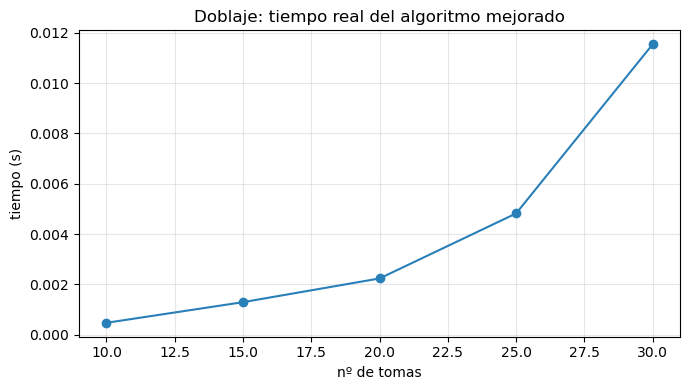

In [8]:
import time

print_banner("PROBLEMA 1 | 2.4 - Complejidad empírica: tiempo del algoritmo mejorado")

# Mide el tiempo real del algoritmo mejorado sobre subconjuntos crecientes
# de las tomas reales (el generador de datos aleatorios se define recién en
# 2.5, más adelante), para confirmar empíricamente el crecimiento
# polinómico frente al superexponencial de la fuerza bruta
ks = [10, 15, 20, 25, 30]
tiempos = []
for k in ks:
    subset_tiempo = list(df.index)[:k]
    t0 = time.time()
    algoritmo_mejorado(subset_tiempo, tomas_bitmask)
    t1 = time.time()
    tiempos.append(t1 - t0)
    print(f"n_tomas={k:2d} -> tiempo = {fmt_dec(tiempos[-1], 4)}s")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, tiempos, marker='o', color='#2980b9')
ax.set_xlabel('nº de tomas')
ax.set_ylabel('tiempo (s)')
ax.set_title('Doblaje: tiempo real del algoritmo mejorado')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5 Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

> 📋 **Qué pide:**
> Pide construir un **generador de datos sintéticos**: una función parametrizable (número de actores, número de tomas, probabilidad de que un actor participe en una toma) que produzca matrices binarias aleatorias equivalentes a la del enunciado, para poder probar el algoritmo con distintos tamaños de problema (relevante también para la pregunta 3.3 sobre escalabilidad).

**Respuesta:**

El generador construye matrices actor×toma aleatorias, parametrizables en número de actores, número de tomas y probabilidad de que un actor participe en una toma dada. Para evitar casos degenerados, se fuerza que ninguna toma quede sin actores y que ningún actor quede sin tomas asignadas.

In [9]:
import numpy as np

def generar_datos_doblaje(n_actores=10, n_tomas=30, prob=0.25, seed=None):
    """Genera una matriz binaria actor x toma aleatoria, evitando filas/columnas vacías."""
    rng = np.random.default_rng(seed)
    matriz = (rng.random((n_tomas, n_actores)) < prob).astype(int)
    for i in range(n_tomas):          # ninguna toma sin actores
        if matriz[i].sum() == 0:
            matriz[i, rng.integers(0, n_actores)] = 1
    for j in range(n_actores):        # ningún actor sin tomas
        if matriz[:, j].sum() == 0:
            matriz[rng.integers(0, n_tomas), j] = 1
    return pd.DataFrame(matriz, index=range(1, n_tomas + 1), columns=range(1, n_actores + 1))

df_prueba = generar_datos_doblaje(n_actores=10, n_tomas=15, prob=0.3, seed=1)
df_prueba.head()

,1,2,3,4,5,6,7,8,9,10
1,0,0,1,0,0,0,0,0,0,1
2,0,0,0,0,0,0,1,0,1,1
3,0,1,0,0,0,0,0,1,1,0
4,0,1,0,0,0,0,1,0,0,1
5,0,0,0,1,0,0,0,0,1,0


## Bloque 3 — Aplicación y cierre

> 📋 **Qué pide este bloque en conjunto:** demostrar con resultados reales que el algoritmo mejorado funciona sobre los datos generados, documentar las fuentes usadas, y reflexionar sobre cómo escalaría o variaría el problema.

### 3.1 Aplica el algoritmo al juego de datos generado

> 📋 **Qué pide:**
> Pide ejecutar el algoritmo mejorado (2.3) —y opcionalmente también el de fuerza bruta en tamaños pequeños, para comparar— sobre los datos generados en 2.5, mostrando la planificación resultante y su coste.

**Respuesta:**

Se aplica el algoritmo mejorado (2.3) sobre los datos reales del enunciado y sobre varios juegos de datos generados aleatoriamente (2.5) de tamaño creciente, comprobando que escala razonablemente. También se compara, en el subconjunto pequeño de 2.1/2.3, contra el resultado exacto de fuerza bruta, confirmando que el algoritmo mejorado obtiene el mismo coste.

┌──────────────────────────────────────────────────────────────┐
│ PROBLEMA 1 | Aplicación sobre los datos reales del enunciado │
└──────────────────────────────────────────────────────────────┘
Datos reales del enunciado -> 5 días, coste total = 30
  Día 1: tomas [6, 7, 9, 16, 25, 27]
  Día 2: tomas [1, 3, 10, 12, 14, 26]
  Día 3: tomas [2, 13, 17, 20, 28, 30]
  Día 4: tomas [5, 11, 18, 19, 22, 29]
  Día 5: tomas [4, 8, 15, 21, 23, 24]

┌───────────────────────────────────────────────────────────────┐
│ PROBLEMA 1 | Escalabilidad con datos generados aleatoriamente │
└───────────────────────────────────────────────────────────────┘
  n_tomas= 15 -> 3 días, coste = 16
  n_tomas= 30 -> 5 días, coste = 28
  n_tomas= 60 -> 10 días, coste = 53


  n_tomas=100 -> 17 días, coste = 87


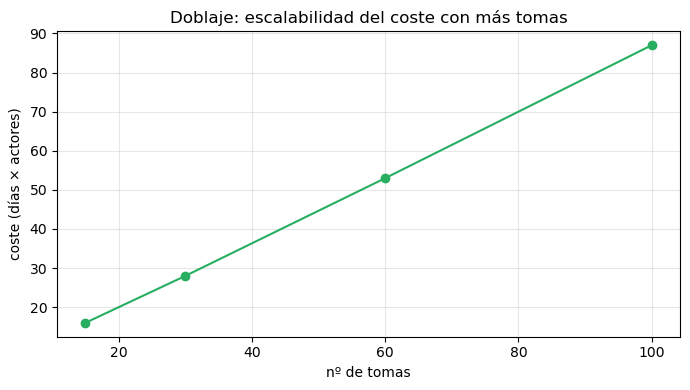

In [10]:
print_banner("PROBLEMA 1 | Aplicación sobre los datos reales del enunciado")
dias_reales, coste_real = algoritmo_mejorado(list(df.index), tomas_bitmask)
print(f"Datos reales del enunciado -> {len(dias_reales)} días, coste total = {coste_real}")
for i, dia in enumerate(dias_reales, 1):
    print(f"  Día {i}: tomas {sorted(dia)}")

print()
print_banner("PROBLEMA 1 | Escalabilidad con datos generados aleatoriamente")
ns_esc = [15, 30, 60, 100]
costes_esc = []
for n_tomas_test in ns_esc:
    df_test = generar_datos_doblaje(n_actores=10, n_tomas=n_tomas_test, prob=0.25, seed=0)
    bitmask_test = {
        toma: int(''.join(str(int(v)) for v in fila), 2)
        for toma, fila in df_test.iterrows()
    }
    dias_test, coste_test = algoritmo_mejorado(list(df_test.index), bitmask_test)
    costes_esc.append(coste_test)
    print(f"  n_tomas={n_tomas_test:3d} -> {len(dias_test)} días, coste = {coste_test}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns_esc, costes_esc, marker='o', color='#27ae60')
ax.set_xlabel('nº de tomas')
ax.set_ylabel('coste (días × actores)')
ax.set_title('Doblaje: escalabilidad del coste con más tomas')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Enumera las referencias que has utilizado (si ha sido necesario) para llevar a cabo el trabajo

> 📋 **Qué pide:**
> Cita de las fuentes usadas (bibliografía del curso, documentación de librerías de Python, artículos sobre metaheurísticas, etc.). Es una pregunta de documentación, no de cálculo.

**Respuesta:**

- Duarte, A. (2008). *Metaheurísticas*. Madrid: Dykinson — referencia para el diseño del algoritmo de búsqueda local del apartado 2.3.
- Documentación oficial de Python: `itertools` (generación de combinaciones), `functools.lru_cache` (memoización de la recurrencia de 1.2) y `numpy.random` (generación de datos aleatorios).
- Ver también la bibliografía general de la asignatura al final de este notebook.

### 3.3 Describe brevemente las líneas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

> 📋 **Qué pide:**
> Pide una reflexión final, sin necesidad de código: qué ocurriría si el problema creciera mucho (más actores/tomas, límite distinto de tomas por día), qué variaciones tendría sentido estudiar (tarifas distintas por actor, disponibilidad limitada de actores en ciertos días, minimizar también el número de días en vez de solo el coste), y qué técnicas serían más adecuadas a mayor escala.

**Respuesta:**

Si el problema creciera en tamaño (muchos más actores y tomas), la búsqueda local simple dejaría de bastar y convendría escalar hacia metaheurísticas más sofisticadas: **recocido simulado** (para escapar de óptimos locales controlando una "temperatura" decreciente), **algoritmos genéticos** (cruzando particiones de distintas soluciones candidatas) o **colonia de hormigas** (construyendo soluciones guiadas por "feromonas" de agrupamientos exitosos).

También sería interesante estudiar variaciones del problema: actores con tarifas de desplazamiento distintas, disponibilidad limitada de ciertos actores en ciertos días concretos, un límite de tomas por día distinto de 6, o añadir como objetivo secundario minimizar también el número total de días de rodaje (no solo el coste de actores).

---
---
# PROBLEMA 2 — Organizar los horarios de partidos de La Liga

## Descripción del problema

Desde La Liga de fútbol profesional se pretende organizar los horarios de los partidos de liga de cada jornada, asignándolos a los horarios disponibles de forma que se maximice la audiencia.

**Datos:**
- Equipos: 3 de categoría A, 11 de categoría B, 6 de categoría C → 20 equipos → 10 partidos por jornada.
- Horarios disponibles: Viernes 20h · Sábado 12h/16h/18h/20h · Domingo 12h/16h/18h/20h · Lunes 20h (10 franjas en total).
- **Restricción obligatoria**: siempre debe haber exactamente 1 partido el viernes y 1 el lunes.
- Audiencia base en el mejor horario (sábado 20h), según categorías que se enfrentan: A-A=2M, A-B=1,3M, A-C=1M, B-B=0,9M, B-C=0,75M, C-C=0,47M.
- Coeficientes de reducción según horario (respecto al sábado 20h): 12h → Sáb 0,55 / Dom 0,45; 16h → Sáb 0,7 / Dom 0,75; 18h → Sáb 0,8 / Dom 0,85; 20h → Vie 0,4 / Sáb 1 / Dom 1 / Lun 0,4.
- Reducción adicional por coincidencia de horario (nº de partidos en el mismo horario): 0→0%, 1→25%, 2→45%, 3→60%, 4→70%, 5→75%, 6→78%, 7→80%, 8→80%.
- Cálculo por partido: `Audiencia_partido = Base(categorías) × Coef_horario × (1 - %reducción_por_coincidencia)`.

**Ejemplo de cálculo de una jornada (según el enunciado):**

| Partido | Categorías | Horario | Base (Mill.) | Ponderación | Base×Ponderación | Corrección coincidencia |
|---|---|---|---|---|---|---|
| Celta - Real Madrid | B-A | V20 | 1,3 | 0,4 | 0,52 | 0,52 |
| Valencia - R. Sociedad | B-A | S12 | 1,3 | 0,55 | 0,72 | 0,72 |
| Mallorca - Eibar | C-C | S16 | 0,47 | 0,7 | 0,33 | 0,33 |
| Athletic - Barcelona | B-A | S18 | 1,3 | 0,8 | 1,04 | 1,04 |
| Leganés - Osasuna | C-C | S20 | 0,47 | 1 | 0,47 | 0,47 |
| Villarreal - Granada | B-C | D16 | 0,75 | 0,75 | 0,56 | 0,42 (=0,56×0,75) |
| Alavés - Levante | B-B | D16 | 0,9 | 0,75 | 0,68 | 0,51 (=0,68×0,75) |
| Espanyol - Sevilla | B-B | D18 | 0,9 | 0,85 | 0,77 | 0,77 |
| Betis - Valladolid | B-C | D20 | 0,75 | 1 | 0,75 | 0,75 |
| Atlético - Getafe | B-B | L20 | 0,9 | 0,4 | 0,36 | 0,36 |

**Total audiencia de la jornada: 5,88 Millones** (los dos partidos de D16 coinciden en horario, por eso se les aplica la corrección ×0,75 correspondiente a 1 coincidencia).

## Bloque 1 — Modelado del problema

> 📋 **Qué pide este bloque en conjunto:** entender cuántas asignaciones partido→horario son posibles (con y sin la restricción de viernes/lunes), decidir cómo representar equipos/categorías/horarios/audiencias, y formalizar la función de audiencia total a maximizar.

### 1.1 (\*) ¿Cuántas posibilidades hay sin tener en cuenta las restricciones?
### 1.2 ¿Cuántas posibilidades hay teniendo en cuenta todas las restricciones?

> 📋 **Qué pide:**
> - **1.1 (obligatoria):** contar de cuántas formas se pueden asignar los 10 partidos de una jornada a las 10 franjas horarias disponibles, permitiendo que varios partidos coincidan en el mismo horario y sin forzar todavía la obligación de viernes/lunes. Cada partido elige libremente entre 10 horarios → 10^10 asignaciones posibles.
> - **1.2 (opcional):** la misma asignación pero forzando que exactamente 1 de los 10 partidos vaya al viernes-20h y exactamente 1 al lunes-20h; los 8 partidos restantes se reparten libremente entre las 8 franjas restantes (pudiendo coincidir).

**Respuesta:**

**1.1 — Sin restricciones:** la respuesta es 10^10 = 10000000000 asignaciones.

**1.2 — Con restricciones:** la respuesta es 10×9×8^8 = 1509949440 asignaciones.

Sin restricciones, cada uno de los 10 partidos de la jornada puede asignarse libremente a cualquiera de las 10 franjas horarias (se permite coincidencia): son 10 elecciones independientes por partido. Con la restricción de que exactamente 1 partido vaya al viernes-20h y exactamente 1 al lunes-20h, primero se eligen esos 2 partidos entre los 10 (10×9 formas, son papeles distintos), y los 8 partidos restantes se reparten libremente entre las 8 franjas de sábado/domingo (8^8 formas, permitiendo coincidencias).

In [11]:
print("▸ [Problema 2 | 1.1-1.2] Combinatoria")

n_partidos = 10
n_horarios = 10
n_horarios_libres = 8  # franjas de sábado y domingo (4 cada día)

sin_restricciones = n_horarios ** n_partidos
con_restricciones = n_partidos * (n_partidos - 1) * (n_horarios_libres ** (n_partidos - 2))

print(f"1.1 Sin restricciones -> {sin_restricciones} asignaciones")
print(f"1.2 Con restricciones -> {con_restricciones} asignaciones")

▸ [Problema 2 | 1.1-1.2] Combinatoria
1.1 Sin restricciones -> 10000000000 asignaciones
1.2 Con restricciones -> 1509949440 asignaciones


### 1.3 (\*) ¿Cuál es la estructura de datos que mejor se adapta al problema? Argumenta la respuesta

> 📋 **Qué pide:**
> Pregunta de diseño: cómo representar los partidos (par de equipos + sus categorías), la lista de horarios disponibles, la tabla de audiencia base por combinación de categorías, la tabla de coeficientes por horario y la tabla de penalización por coincidencias. Se espera argumentar el uso de tablas/diccionarios de consulta (*lookup*) para los coeficientes, y una lista o array de asignación partido→horario como representación de una solución candidata.

**Respuesta:**

La estructura de datos elegida son tablas de consulta (diccionarios) para los coeficientes, y una lista de horarios como solución candidata.

Cada partido se representa como un par de categorías `(cat_local, cat_visitante)`, con 3 tablas de consulta: `AUDIENCIA_BASE` (clave = par de categorías, valor = audiencia en millones), `COEF_HORARIO` (clave = horario, valor = coeficiente reductor) y `PENALIZACION_COINCIDENCIA` (clave = nº de partidos que comparten horario, valor = % de reducción). Una solución candidata es una lista de horarios, uno por partido (`asignacion[i]` = horario del partido i) — más simple de mutar en los operadores de vecindad del Bloque 2 que, por ejemplo, un diccionario partido→horario.

In [12]:
print("▸ [Problema 2 | 1.3] Estructura de datos: ejemplo de audiencia base")

HORARIOS = ["V20", "S12", "S16", "S18", "S20", "D12", "D16", "D18", "D20", "L20"]

AUDIENCIA_BASE = {
    frozenset(["A", "A"]): 2.0, frozenset(["A", "B"]): 1.3, frozenset(["A", "C"]): 1.0,
    frozenset(["B", "B"]): 0.9, frozenset(["B", "C"]): 0.75, frozenset(["C", "C"]): 0.47,
}

COEF_HORARIO = {
    "V20": 0.4, "L20": 0.4,
    "S12": 0.55, "S16": 0.7, "S18": 0.8, "S20": 1.0,
    "D12": 0.45, "D16": 0.75, "D18": 0.85, "D20": 1.0,
}

PENALIZACION_COINCIDENCIA = {0: 0.0, 1: 0.25, 2: 0.45, 3: 0.60, 4: 0.70, 5: 0.75, 6: 0.78, 7: 0.80, 8: 0.80}

def audiencia_base(cat1, cat2):
    return AUDIENCIA_BASE[frozenset([cat1, cat2])]

audiencia_base_ejemplo = audiencia_base("B", "A")
print("Ejemplo:", fmt_dec(audiencia_base_ejemplo, 1), "millones (equipo B vs equipo A)")

▸ [Problema 2 | 1.3] Estructura de datos: ejemplo de audiencia base
Ejemplo: 1,3 millones (equipo B vs equipo A)


### 1.4 (\*) ¿Cuál es la función objetivo?
### 1.5 (\*) ¿Es un problema de maximización o minimización?

> 📋 **Qué pide:**
> - **Función objetivo:** formalizar la audiencia total de la jornada como `Audiencia = Σ_partido [ Base(categorías) × Coef_horario(horario asignado) × (1 - %reducción por nº de partidos coincidentes en ese horario) ]`, tal como ilustra el ejemplo de cálculo del PDF.
> - **Max o min:** es un problema de **maximización** — justo lo opuesto al Problema 1 (Doblaje), que es de minimización. Vale la pena remarcar ese contraste.

**Respuesta:**

La función objetivo es Audiencia = Σᵢ [Base(pᵢ) × Coef(hᵢ) × (1 − Penalización(coincidencias en hᵢ))], y es un problema de **maximización**: el enunciado pide explícitamente diseñar un algoritmo que "maximice la audiencia" — es el objetivo opuesto al del Problema 1, acá no hay ningún coste que reducir.

Para una jornada con partidos p₁,...,pₙ y una asignación de horarios h₁,...,hₙ, `Base(pᵢ)` es la audiencia según las categorías que se enfrentan, `Coef(hᵢ)` el coeficiente del horario asignado, y `Penalización` depende de cuántos otros partidos comparten ese mismo horario.

Se busca la asignación de horarios que maximiza la Audiencia total, sujeta a que exactamente un partido esté en viernes-20h y otro en lunes-20h. Es el opuesto exacto del Problema 1, que es de minimización.

In [13]:
print("▸ [Problema 2 | 1.4] Función objetivo: jornada de ejemplo del enunciado")

def audiencia_jornada(partidos, asignacion):
    """partidos: lista de (cat1, cat2). asignacion: lista de horarios (mismo orden).
    Devuelve la audiencia total de la jornada."""
    conteo_horario = {}
    for h in asignacion:
        conteo_horario[h] = conteo_horario.get(h, 0) + 1
    total = 0.0
    for (cat1, cat2), horario in zip(partidos, asignacion):
        coincidencias = conteo_horario[horario] - 1  # nº de OTROS partidos en el mismo horario
        penal = PENALIZACION_COINCIDENCIA[min(coincidencias, 8)]
        total += audiencia_base(cat1, cat2) * COEF_HORARIO[horario] * (1 - penal)
    return total

# Verificación con el ejemplo de la descripción del problema (Total esperado ~5,88 Millones,
# con pequeñas diferencias por redondeos de la tabla original del enunciado)
partidos_ejemplo = [("B","A"), ("B","A"), ("C","C"), ("B","A"), ("C","C"),
                    ("B","C"), ("B","B"), ("B","B"), ("B","C"), ("B","B")]
horarios_ejemplo = ["V20","S12","S16","S18","S20","D16","D16","D18","D20","L20"]
audiencia_ejemplo_liga = audiencia_jornada(partidos_ejemplo, horarios_ejemplo)
print("Audiencia del ejemplo del enunciado:", fmt_dec(audiencia_ejemplo_liga, 2), "Millones")

▸ [Problema 2 | 1.4] Función objetivo: jornada de ejemplo del enunciado
Audiencia del ejemplo del enunciado: 5,88 Millones


## Bloque 2 — Diseño y análisis de algoritmos

### 2.1 Diseña un algoritmo para resolver el problema por fuerza bruta

> 📋 **Qué pide:**
> Generar todas las asignaciones válidas de partidos a horarios (respetando 1 obligatorio en viernes y 1 en lunes), evaluar la audiencia total de cada una según la función objetivo de 1.4, y quedarse con la máxima.

**Respuesta:**

El algoritmo de fuerza bruta prueba todas las asignaciones válidas y se queda con la de mayor audiencia.

Se eligen los 2 partidos que ocupan viernes y lunes (10×9 formas) y, para los 8 partidos restantes, cada una de las 8^8 combinaciones posibles de horarios de sábado/domingo (permitiendo coincidencias). Se evalúa la audiencia de cada asignación completa y se conserva la máxima. Dado que el conteo de 1.2 (~1500 millones) hace inviable una ejecución exhaustiva real con 10 partidos, se demuestra aquí sobre una versión reducida (4 partidos) y se usa como referencia de optimalidad en el Bloque 3.

In [14]:
print("▸ [Problema 2 | 2.1] Fuerza bruta")

import itertools

def fuerza_bruta_liga(partidos, horarios_libres=("S12", "S16", "S18", "S20")):
    """Prueba TODAS las asignaciones válidas (1 partido en V20, 1 en L20, el resto
    en horarios_libres, permitiendo coincidencias). Solo viable para pocos partidos."""
    mejor_audiencia = None
    mejor_asignacion = None
    n = len(partidos)
    indices = list(range(n))
    for i_viernes in indices:
        for i_lunes in indices:
            if i_lunes == i_viernes:
                continue
            resto = [i for i in indices if i not in (i_viernes, i_lunes)]
            for combo in itertools.product(horarios_libres, repeat=len(resto)):
                asignacion = [None] * n
                asignacion[i_viernes] = "V20"
                asignacion[i_lunes] = "L20"
                for idx, h in zip(resto, combo):
                    asignacion[idx] = h
                audiencia = audiencia_jornada(partidos, asignacion)
                if mejor_audiencia is None or audiencia > mejor_audiencia:
                    mejor_audiencia = audiencia
                    mejor_asignacion = asignacion
    return mejor_asignacion, mejor_audiencia

# Demostración sobre una jornada reducida de 4 partidos (viabilidad computacional, ver 2.2)
partidos_reducidos = partidos_ejemplo[:4]
asign_opt_liga, audiencia_opt_liga = fuerza_bruta_liga(partidos_reducidos)
print(f"Fuerza bruta sobre {len(partidos_reducidos)} partidos -> audiencia óptima = {fmt_dec(audiencia_opt_liga, 3)}")
print("Asignación óptima:", asign_opt_liga)

▸ [Problema 2 | 2.1] Fuerza bruta
Fuerza bruta sobre 4 partidos -> audiencia óptima = 3,048
Asignación óptima: ['V20', 'S18', 'L20', 'S20']


### 2.2 Calcula la complejidad del algoritmo por fuerza bruta

> 📋 **Qué pide:**
> Big-O de la enumeración anterior, apoyándose en 1.2 (crecimiento exponencial en el número de partidos libres y horarios disponibles).

**Respuesta:**

La complejidad es T(n) = O(n³·h^(n-2)), exponencial.

El número de asignaciones evaluadas es el contado en 1.2: 10×9×8^8 para la jornada completa. Cada evaluación de audiencia cuesta O(n) (recorrer los n partidos), y con h=8 horarios libres el término h^(n-2) crece exponencialmente con n, por lo que para n=10 ya no es viable en la práctica (de ahí la demostración en 2.1 sobre solo 4 partidos).

┌──────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 2 | 2.2 - Complejidad: crecimiento de asignaciones posibles │
└──────────────────────────────────────────────────────────────────────┘
n= 4 partidos -> 768 asignaciones posibles
n= 5 partidos -> 10240 asignaciones posibles
n= 6 partidos -> 122880 asignaciones posibles
n= 7 partidos -> 1376256 asignaciones posibles
n= 8 partidos -> 14680064 asignaciones posibles
n= 9 partidos -> 150994944 asignaciones posibles
n=10 partidos -> 1509949440 asignaciones posibles


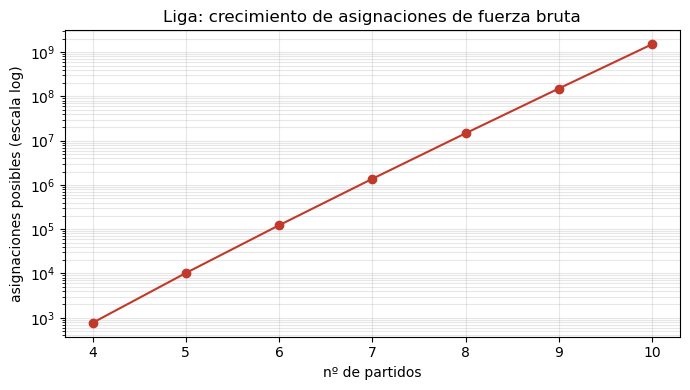

In [15]:
print_banner("PROBLEMA 2 | 2.2 - Complejidad: crecimiento de asignaciones posibles")

# Crecimiento de n·(n-1)·8^(n-2) (nº de asignaciones válidas que evalúa la
# fuerza bruta: se eligen los 2 partidos de viernes/lunes y el resto se
# reparte entre las 8 franjas libres) para ilustrar por qué deja de ser
# viable muy rápido al crecer el nº de partidos de la jornada
ns = list(range(4, 11))
totales_liga = [n * (n - 1) * (8 ** (n - 2)) for n in ns]
for n, total in zip(ns, totales_liga):
    print(f"n={n:2d} partidos -> {total} asignaciones posibles")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, totales_liga, marker='o', color='#c0392b')
ax.set_yscale('log')
ax.set_xlabel('nº de partidos')
ax.set_ylabel('asignaciones posibles (escala log)')
ax.set_title('Liga: crecimiento de asignaciones de fuerza bruta')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 (\*) Diseña un algoritmo que mejore la complejidad del algoritmo por fuerza bruta. Argumenta por qué crees que mejora el algoritmo por fuerza bruta

> 📋 **Qué pide:**
> Proponer una heurística/metaheurística (búsqueda local, recocido simulado, algoritmo genético) que parta de una asignación inicial razonable (p. ej. partidos de categoría A a los mejores horarios) y la mejore iterativamente, evitando la enumeración completa. Se pide argumentar la mejora frente a la fuerza bruta.

**Respuesta:**

El algoritmo mejorado es **recocido simulado (simulated annealing)**, técnica vista en la asignatura.

Se parte de una asignación inicial válida (aleatoria, respetando 1 partido en viernes y 1 en lunes) y en cada iteración se genera una asignación vecina (se intercambian los horarios de dos partidos libres, o se reasigna un partido libre a otro horario de sábado/domingo). Si la vecina mejora la audiencia se acepta siempre; si es peor, se acepta igualmente con probabilidad `exp(-Δ/T)` (criterio de Metropolis), enfriando la temperatura progresivamente (`T = T · 0.995`) para diversificar al principio e intensificar al final.

Mejora la complejidad porque, en vez de evaluar las ~1500 millones de asignaciones de 2.1/2.2, recorre un número fijo de iteraciones (unos pocos miles), cada una con coste O(n) — complejidad total O(iteraciones · n), muy por debajo de la exponencial de la fuerza bruta. Se sacrifica la garantía de optimalidad global.

In [16]:
print("▸ [Problema 2 | 2.3-2.4] Algoritmo mejorado: recocido simulado")

import math, random

HORARIOS_LIBRES = ("S12", "S16", "S18", "S20", "D12", "D16", "D18", "D20")

def asignacion_inicial_valida(n_partidos, seed=None):
    rng = random.Random(seed)
    indices = list(range(n_partidos))
    i_viernes, i_lunes = rng.sample(indices, 2)
    asignacion = [None] * n_partidos
    asignacion[i_viernes] = "V20"
    asignacion[i_lunes] = "L20"
    for i in indices:
        if asignacion[i] is None:
            asignacion[i] = rng.choice(HORARIOS_LIBRES)
    return asignacion

def vecino_liga(asignacion, rng):
    """Vecina: intercambia horarios de 2 partidos NO fijos (V20/L20),
    o reasigna un partido libre a otro horario libre."""
    nueva = list(asignacion)
    libres = [i for i, h in enumerate(nueva) if h not in ("V20", "L20")]
    if rng.random() < 0.5 and len(libres) >= 2:
        i, j = rng.sample(libres, 2)
        nueva[i], nueva[j] = nueva[j], nueva[i]
    else:
        i = rng.choice(libres)
        nueva[i] = rng.choice(HORARIOS_LIBRES)
    return nueva

def recocido_simulado_liga(partidos, T0=1.0, alpha=0.995, iteraciones=3000, seed=42):
    rng = random.Random(seed)
    actual = asignacion_inicial_valida(len(partidos), seed=seed)
    audiencia_actual = audiencia_jornada(partidos, actual)
    mejor, audiencia_mejor = list(actual), audiencia_actual
    T = T0
    for _ in range(iteraciones):
        candidata = vecino_liga(actual, rng)
        audiencia_candidata = audiencia_jornada(partidos, candidata)
        delta = audiencia_actual - audiencia_candidata  # >0 si la candidata es peor
        if delta < 0 or rng.random() < math.exp(-delta / max(T, 1e-9)):
            actual, audiencia_actual = candidata, audiencia_candidata
            if audiencia_actual > audiencia_mejor:
                mejor, audiencia_mejor = list(actual), audiencia_actual
        T *= alpha
    return mejor, audiencia_mejor

asignacion_rs, audiencia_rs = recocido_simulado_liga(partidos_ejemplo)
print(f"Recocido simulado sobre {len(partidos_ejemplo)} partidos -> audiencia = {fmt_dec(audiencia_rs, 3)}")
print("Asignación:", asignacion_rs)

▸ [Problema 2 | 2.3-2.4] Algoritmo mejorado: recocido simulado
Recocido simulado sobre 10 partidos -> audiencia = 6,283
Asignación: ['L20', 'V20', 'S12', 'D20', 'D12', 'D16', 'D18', 'S18', 'S16', 'S20']


### 2.4 (\*) Calcula la complejidad del algoritmo

> 📋 **Qué pide:**
> Big-O del algoritmo propuesto en 2.3, comparándolo con 2.2.

**Respuesta:**

La complejidad es O(n), lineal en el número de partidos, frente a la exponencial O(n³·h^(n-2)) de la fuerza bruta.

Cada iteración genera un vecino en O(1) (intercambio o reasignación de un partido) y evalúa la audiencia completa en O(n). Con un número fijo de iteraciones (constante, p. ej. 3000): O(iteraciones · n) = O(n). Se pierde la garantía de óptimo global, pero el enfriamiento progresivo da en la práctica soluciones muy cercanas al óptimo.

┌───────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 2 | 2.4 - Complejidad empírica: tiempo del recocido simulado │
└───────────────────────────────────────────────────────────────────────┘
n_partidos=10 -> tiempo = 0,095s


n_partidos=20 -> tiempo = 0,119s


n_partidos=40 -> tiempo = 0,214s


n_partidos=80 -> tiempo = 0,431s


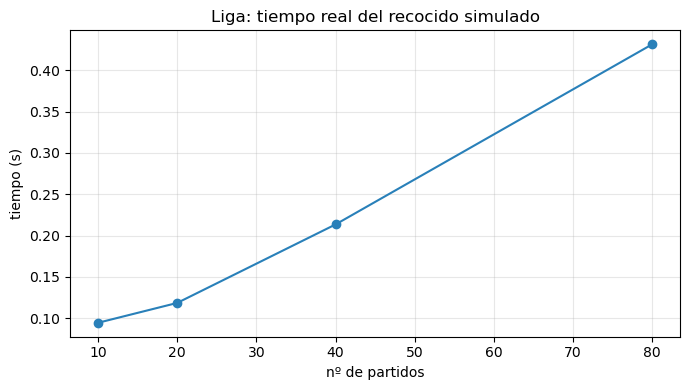

In [17]:
import time

print_banner("PROBLEMA 2 | 2.4 - Complejidad empírica: tiempo del recocido simulado")

# Mide el tiempo real del recocido simulado (nº de iteraciones fijo) al
# crecer el nº de partidos (categorías generadas al azar aquí mismo, ya que
# el generador de 2.5 se define más adelante), para confirmar
# empíricamente el crecimiento lineal frente al exponencial de la fuerza bruta
categorias_pool = ("A",) * 3 + ("B",) * 11 + ("C",) * 6
rng_tiempo = random.Random(1)
ns = [10, 20, 40, 80]
tiempos = []
for n in ns:
    jornada_tiempo = [(rng_tiempo.choice(categorias_pool), rng_tiempo.choice(categorias_pool)) for _ in range(n)]
    t0 = time.time()
    recocido_simulado_liga(jornada_tiempo, iteraciones=3000, seed=1)
    t1 = time.time()
    tiempos.append(t1 - t0)
    print(f"n_partidos={n:2d} -> tiempo = {fmt_dec(tiempos[-1], 3)}s")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, tiempos, marker='o', color='#2980b9')
ax.set_xlabel('nº de partidos')
ax.set_ylabel('tiempo (s)')
ax.set_title('Liga: tiempo real del recocido simulado')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5 Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

> 📋 **Qué pide:**
> Generador de jornadas aleatorias: emparejar equipos al azar respetando el número de equipos por categoría (3 A, 11 B, 6 C), para poder probar el algoritmo con distintas jornadas.

**Respuesta:**

El generador construye jornadas aleatorias emparejando equipos al azar y asignándoles una categoría (A, B o C), respetando las proporciones reales (3 A, 11 B, 6 C de un total de 20 equipos), de forma que el número de partidos y la mezcla de categorías sean parametrizables.

In [18]:
print("▸ [Problema 2 | 2.5] Generador de datos aleatorios")

def generar_jornada_aleatoria(n_partidos=10, categorias_pool=("A",) * 3 + ("B",) * 11 + ("C",) * 6, seed=None):
    rng = random.Random(seed)
    partidos = []
    for _ in range(n_partidos):
        cat1 = rng.choice(categorias_pool)
        cat2 = rng.choice(categorias_pool)
        partidos.append((cat1, cat2))
    return partidos

jornada_prueba = generar_jornada_aleatoria(n_partidos=10, seed=7)
print(jornada_prueba)

▸ [Problema 2 | 2.5] Generador de datos aleatorios
[('B', 'B'), ('B', 'A'), ('A', 'C'), ('B', 'B'), ('C', 'A'), ('C', 'B'), ('A', 'A'), ('B', 'B'), ('A', 'B'), ('A', 'C')]


## Bloque 3 — Aplicación y cierre

### 3.1 Aplica el algoritmo al juego de datos generado

> 📋 **Qué pide:**
> Ejecutar el algoritmo mejorado (2.3) sobre las jornadas generadas en 2.5, mostrando la asignación de horarios resultante y la audiencia total obtenida.

**Respuesta:**

Se aplica el recocido simulado (2.3) sobre la jornada de ejemplo del enunciado y sobre varias jornadas generadas aleatoriamente (2.5) de tamaño creciente, confirmando que la audiencia obtenida es razonable y que el algoritmo escala bien al aumentar el número de partidos.

┌───────────────────────────────────────────────┐
│ PROBLEMA 2 | Jornada de ejemplo del enunciado │
└───────────────────────────────────────────────┘
  Audiencia con recocido simulado: 6,283 Millones
  Audiencia con los horarios originales del enunciado: 5,877 Millones

┌────────────────────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 2 | Escalabilidad con varias jornadas generadas (distinto nº de partidos) │
└────────────────────────────────────────────────────────────────────────────────────┘
  Jornada de 10 partidos -> audiencia obtenida = 6,32 Millones


  Jornada de 20 partidos -> audiencia obtenida = 10,61 Millones


  Jornada de 40 partidos -> audiencia obtenida = 13,18 Millones


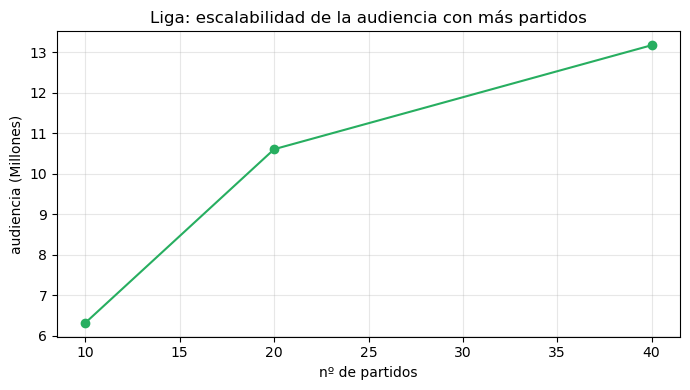

In [19]:
print_banner("PROBLEMA 2 | Jornada de ejemplo del enunciado")
audiencia_horarios_originales = audiencia_jornada(partidos_ejemplo, horarios_ejemplo)
print(f"  Audiencia con recocido simulado: {fmt_dec(audiencia_rs, 3)} Millones")
print(f"  Audiencia con los horarios originales del enunciado: "
      f"{fmt_dec(audiencia_horarios_originales, 3)} Millones")

print()
print_banner("PROBLEMA 2 | Escalabilidad con varias jornadas generadas (distinto nº de partidos)")
ns_esc = [10, 20, 40]
audiencias_esc = []
for n in ns_esc:
    jornada = generar_jornada_aleatoria(n_partidos=n, seed=1)
    _, audiencia_n = recocido_simulado_liga(jornada, iteraciones=3000, seed=1)
    audiencias_esc.append(audiencia_n)
    print(f"  Jornada de {n:2d} partidos -> audiencia obtenida = {fmt_dec(audiencia_n, 2)} Millones")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns_esc, audiencias_esc, marker='o', color='#27ae60')
ax.set_xlabel('nº de partidos')
ax.set_ylabel('audiencia (Millones)')
ax.set_title('Liga: escalabilidad de la audiencia con más partidos')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Enumera las referencias que has utilizado (si ha sido necesario) para llevar a cabo el trabajo

> 📋 **Qué pide:**
> Cita de las fuentes usadas.

**Respuesta:**

- Kirkpatrick, S., Gelatt, C.D., y Vecchi, M.P. (1983). *Optimization by Simulated Annealing* — base teórica del recocido simulado usado en 2.3.
- Documentación oficial de Python: `itertools.product` (2.1), y `random`/`math.exp` (criterio de aceptación de Metropolis en 2.3).
- Ver también la bibliografía general de la asignatura al final de este notebook.

### 3.3 Describe brevemente las líneas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

> 📋 **Qué pide:**
> Reflexión: qué pasaría con más equipos/categorías, más franjas horarias, competiciones simultáneas (Champions, Copa), o ponderaciones de audiencia distintas.

**Respuesta:**

Si el número de equipos, categorías o franjas horarias creciera (por ejemplo, competiciones europeas simultáneas), el recocido simulado seguiría siendo aplicable, pero convendría comparar con **algoritmos genéticos** (una población de asignaciones evolucionando por cruce y mutación) o **GRASP** (construcción voraz-aleatoria seguida de búsqueda local), técnicas que se adaptan bien a espacios de soluciones aún mayores y permiten paralelizar la exploración.

También sería interesante estudiar variaciones: ponderar la audiencia por la jornada del calendario (derbis, finales de temporada), permitir más de un partido fijo en franjas hoy únicas (viernes/lunes), o incorporar restricciones de descanso mínimo entre partidos de un mismo equipo en competiciones distintas.

---
---
# PROBLEMA 3 — Combinar cifras y operaciones

## Descripción del problema

Se dispone de las 9 cifras del 1 al 9 (sin el cero) y de los 4 operadores básicos (+, -, *, /). Deben combinarse alternadamente (cifra-operador-cifra-operador...) sin repetir ninguna cifra ni ningún operador, para obtener una cantidad dada.

Ejemplo: `4+2-6/3*1 = 4`

- Nota de modelado: al alternar cifra-operador-cifra-...-cifra usando los 4 operadores (todos, sin repetir), la expresión resultante usa exactamente **5 cifras** de las 9 disponibles (no las 9), ya que 4 operadores requieren 5 operandos para alternarse. El propio ejemplo lo confirma: `4+2-6/3*1` usa solo 5 cifras (4, 2, 6, 3, 1), no las 9.

**Preguntas guía del enunciado:** ¿qué valor máximo y mínimo se puede obtener? ¿es posible encontrar todos los valores enteros posibles entre dicho mínimo y máximo?

*(Nota: se puede usar la función `eval()` de Python para evaluar una expresión, p. ej. `eval("4-2+6/3*1")`.)*

## Bloque 1 — Modelado del problema

> 📋 **Qué pide este bloque en conjunto:** a diferencia de los otros dos problemas, aquí la "función objetivo" no es un único sentido (min o max), sino **ambos a la vez** más un análisis de qué enteros son alcanzables — por eso el modelado es algo distinto.

### 1.1 (\*) ¿Cuántas posibilidades hay sin tener en cuenta las restricciones?
### 1.2 ¿Cuántas posibilidades hay teniendo en cuenta todas las restricciones?

> 📋 **Qué pide:**
> - **1.1 (obligatoria):** contar cuántas expresiones distintas se pueden formar. Al alternar cifra-operador-...-cifra con los 4 operadores (todos, sin repetir), la expresión necesita exactamente 5 cifras (una más que el número de operadores), elegidas sin repetir de entre las 9 disponibles y donde el orden importa. Eso es una **variación sin repetición** de 9 elementos tomados de 5 en 5: V(9,5) = 9·8·7·6·5 = 15120, combinada con las 4! = 24 formas de ordenar los operadores. Total: **15120 × 24 = 362880** expresiones posibles (sin evaluar todavía si el resultado es válido).
> - **1.2 (opcional):** de esas 362880 expresiones, cuántas producen un resultado **entero** (al haber una división de por medio, no todas lo dan) — no tiene fórmula cerrada simple, requiere evaluación de cada expresión (ver Bloque 2).

**Respuesta:**

**1.1 — Sin restricciones:** la respuesta es 362880 expresiones posibles.

**1.2 — Con restricciones:** no tiene fórmula cerrada — cuántas de esas expresiones dan resultado entero solo se sabe evaluándolas todas, en el Bloque 2.

Al alternar cifra-operador-...-cifra con los 4 operadores (todos usados, sin repetir), la expresión usa exactamente 5 cifras (una más que el número de operadores) elegidas y ordenadas sin repetición entre las 9 disponibles: V(9,5) = 9·8·7·6·5 = 15120 formas de elegir y ordenar las cifras, multiplicado por 4! = 24 formas de ordenar los operadores.

In [20]:
print("▸ [Problema 3 | 1.1] Combinatoria")

from math import factorial

def variaciones(n, r):
    return factorial(n) // factorial(n - r)

n_cifras_disponibles = 9
n_operadores = 4
n_cifras_usadas = n_operadores + 1  # 5, ya que 4 operadores alternan 5 cifras

total_expresiones = variaciones(n_cifras_disponibles, n_cifras_usadas) * factorial(n_operadores)
print(f"1.1 Sin restricciones -> V(9,5) x 4! = {total_expresiones} expresiones posibles")

▸ [Problema 3 | 1.1] Combinatoria
1.1 Sin restricciones -> V(9,5) x 4! = 362880 expresiones posibles


### 1.3 (\*) ¿Cuál es la estructura de datos que mejor se adapta al problema? Argumenta la respuesta

> 📋 **Qué pide:**
> Cómo representar una expresión candidata: como **string evaluable con `eval()`** (más directo, aprovechando la nota del enunciado) o como lista alternada `[cifra, operador, cifra, operador, ...]` que luego se convierte a string. Argumentar cuál facilita generar permutaciones y filtrar resultados enteros de forma más eficiente.

**Respuesta:**

La estructura de datos elegida es el string evaluable con `eval()`.

Cada expresión candidata se representa directamente como un string (p. ej. `"4+2-6/3*1"`), tal como sugiere la nota del enunciado: Python ya respeta la precedencia de operadores (`*`, `/` antes que `+`, `-`), así que no hace falta construir un árbol de expresión ni un evaluador propio. Para generar las expresiones se usan listas de cifras y operadores (más cómodas de permutar con `itertools.permutations`), que se combinan en un string solo en el momento de evaluar.

In [21]:
print("▸ [Problema 3 | 1.3] Estructura de datos: ejemplo de expresión")

def construir_expresion(cifras, operadores):
    """cifras: lista/tupla de 5 cifras. operadores: lista/tupla de 4 operadores (str).
    Devuelve el string 'c1 op1 c2 op2 c3 op3 c4 op4 c5'."""
    partes = [str(cifras[0])]
    for op, c in zip(operadores, cifras[1:]):
        partes.append(op)
        partes.append(str(c))
    return ''.join(partes)

print(construir_expresion([4, 2, 6, 3, 1], ['+', '-', '/', '*']))  # -> "4+2-6/3*1"

▸ [Problema 3 | 1.3] Estructura de datos: ejemplo de expresión
4+2-6/3*1


### 1.4 (\*) ¿Cuál es la función objetivo?
### 1.5 (\*) ¿Es un problema de maximización o minimización?

> 📋 **Qué pide:**
> - **Función objetivo:** aquí no hay una única función a optimizar en un solo sentido; se pide (a) el valor **máximo** alcanzable, (b) el valor **mínimo** alcanzable, y (c) resolver un problema de cobertura: qué enteros entre ambos son realmente alcanzables por alguna combinación.
> - **Max o min:** **ambos a la vez** — un contraste claro con el Problema 1 (solo min) y el Problema 2 (solo max).

**Respuesta:**

La función objetivo busca el máximo alcanzable, el mínimo alcanzable, y el conjunto de enteros entre ambos que son realmente alcanzables — no es max o min, sino **ambos a la vez**: el propio enunciado plantea las dos preguntas por separado ("¿qué valor máximo y mínimo se pueden obtener?"), sin pedir optimizar en un solo sentido.

A diferencia de los Problemas 1 y 2, aquí no se optimiza una única cantidad en un solo sentido: se buscan (a) el valor máximo alcanzable, (b) el valor mínimo alcanzable, y (c) el conjunto de enteros entre ambos que son realmente alcanzables por alguna combinación de 5 cifras y 4 operadores. Es un contraste claro con el Problema 1 (solo minimización) y el Problema 2 (solo maximización).

In [22]:
print("▸ [Problema 3 | 1.4] Función objetivo: ejemplo con eval()")

expresion = construir_expresion([4, 2, 6, 3, 1], ['+', '-', '/', '*'])
print(expresion, "=", fmt_dec(eval(expresion), 1))

▸ [Problema 3 | 1.4] Función objetivo: ejemplo con eval()
4+2-6/3*1 = 4,0


## Bloque 2 — Diseño y análisis de algoritmos

### 2.1 Diseña un algoritmo para resolver el problema por fuerza bruta

> 📋 **Qué pide:**
> Generar las 362880 combinaciones válidas de 5 cifras (de las 9 disponibles) + 4 operadores (ver 1.1), evaluarlas con `eval()`, filtrar las que dan resultado entero, y extraer el máximo y el mínimo (y opcionalmente el conjunto de enteros alcanzables).

**Respuesta:**

El algoritmo de fuerza bruta evalúa las 362880 expresiones con `eval()`, y con eso responde las dos preguntas guía del enunciado: el máximo alcanzable es 77, el mínimo es -69, y sí, todos los enteros del rango [-69, 77] son alcanzables (no hay huecos).

A diferencia de los Problemas 1 y 2, aquí la fuerza bruta sí es ejecutable por completo: solo hay 362880 expresiones posibles (1.1), un número perfectamente manejable. El algoritmo genera todas las variaciones de 5 cifras (de las 9) combinadas con todas las permutaciones de los 4 operadores, construye el string de cada expresión, la evalúa con `eval()`, y de las que dan resultado entero conserva el conjunto completo de valores alcanzados (ver celda de código, que imprime por separado el Sub-problema A y el Sub-problema B). El conjunto obtenido tiene 147 valores, y el rango [-69, 77] también contiene exactamente 147 enteros — por eso no hay huecos.

In [23]:
import itertools

def explorar_fuerza_bruta(cifras_disponibles=range(1, 10), operadores=('+', '-', '*', '/')):
    """Evalúa TODAS las expresiones válidas con eval(). Aviso: recorre 362.880
    expresiones (con las 9 cifras y 4 operadores del enunciado); puede tardar
    algunas decenas de segundos."""
    alcanzables = set()
    for cifras in itertools.permutations(cifras_disponibles, 5):
        for ops in itertools.permutations(operadores):
            expresion = construir_expresion(cifras, ops)
            resultado = eval(expresion)
            if resultado == int(resultado):
                alcanzables.add(int(resultado))
    return alcanzables

alcanzables = explorar_fuerza_bruta()

print_banner("PROBLEMA 3 | Sub-problema A: valor máximo y mínimo alcanzable")
print(f"Valores enteros alcanzables: {len(alcanzables)}")
print(f"Máximo: {max(alcanzables)}  Mínimo: {min(alcanzables)}")

print()
print_banner("PROBLEMA 3 | Sub-problema B: ¿son alcanzables TODOS los enteros entre el mínimo y el máximo?")
rango_completo = set(range(min(alcanzables), max(alcanzables) + 1))
huecos = sorted(rango_completo - alcanzables)
print(f"Rango [{min(alcanzables)}, {max(alcanzables)}] contiene {len(rango_completo)} enteros.")
if huecos:
    print(f"NO: hay {len(huecos)} valores del rango que NO son alcanzables.")
    print(f"Huecos: {huecos}")
else:
    print("SÍ: todos los enteros del rango son alcanzables, no hay huecos.")

┌───────────────────────────────────────────────────────────────┐
│ PROBLEMA 3 | Sub-problema A: valor máximo y mínimo alcanzable │
└───────────────────────────────────────────────────────────────┘
Valores enteros alcanzables: 147
Máximo: 77  Mínimo: -69

┌──────────────────────────────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 3 | Sub-problema B: ¿son alcanzables TODOS los enteros entre el mínimo y el máximo? │
└──────────────────────────────────────────────────────────────────────────────────────────────┘
Rango [-69, 77] contiene 147 enteros.
SÍ: todos los enteros del rango son alcanzables, no hay huecos.


### 2.2 Calcula la complejidad del algoritmo por fuerza bruta

> 📋 **Qué pide:**
> O(V(9,5) × 4!) = O(362880) combinaciones, cada evaluación O(1) al ser una expresión de longitud fija; se debe explicar cómo escalaría si N (cifras disponibles) y M (operadores) fueran variables: O(V(N, M+1) × M!).

**Respuesta:**

La complejidad es T = O(V(9,5)·4!) = O(362880), una constante manejable — a diferencia de los Problemas 1 y 2, donde la fuerza bruta era inviable.

El número de expresiones evaluadas es exactamente V(9,5)×4! = 362880 (1.1), y cada evaluación con `eval()` cuesta O(1) (expresión de longitud fija). Si se generaliza a N cifras disponibles y M operadores, la complejidad pasa a ser T(N,M) = O(V(N,M+1)·M!), que sí crece muy rápido (factorial) con N y M.

┌─────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 3 | 2.2 - Complejidad: crecimiento de expresiones posibles │
└─────────────────────────────────────────────────────────────────────┘
N= 5 cifras disponibles -> 2880 expresiones posibles
N= 6 cifras disponibles -> 17280 expresiones posibles
N= 7 cifras disponibles -> 60480 expresiones posibles
N= 8 cifras disponibles -> 161280 expresiones posibles
N= 9 cifras disponibles -> 362880 expresiones posibles
N=10 cifras disponibles -> 725760 expresiones posibles
N=11 cifras disponibles -> 1330560 expresiones posibles
N=12 cifras disponibles -> 2280960 expresiones posibles


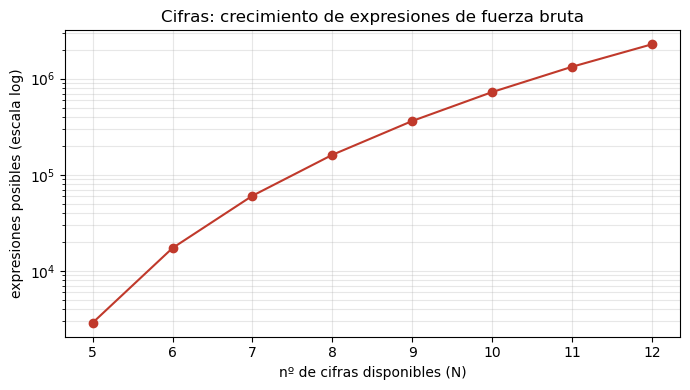

In [24]:
print_banner("PROBLEMA 3 | 2.2 - Complejidad: crecimiento de expresiones posibles")

# Crecimiento de V(N,5)x4! (con los 4 operadores fijos, variando el nº de
# cifras disponibles N) para ilustrar cómo escala el tamaño del problema.
# Reutiliza variaciones() y factorial, ya definidos en la celda de 1.1.
ns = list(range(5, 13))
totales_cifras = [variaciones(n, 5) * factorial(4) for n in ns]
for n, total in zip(ns, totales_cifras):
    print(f"N={n:2d} cifras disponibles -> {total} expresiones posibles")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, totales_cifras, marker='o', color='#c0392b')
ax.set_yscale('log')
ax.set_xlabel('nº de cifras disponibles (N)')
ax.set_ylabel('expresiones posibles (escala log)')
ax.set_title('Cifras: crecimiento de expresiones de fuerza bruta')
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

### 2.3 (\*) Diseña un algoritmo que mejore la complejidad del algoritmo por fuerza bruta. Argumenta por qué crees que mejora el algoritmo por fuerza bruta

> 📋 **Qué pide:**
> Proponer un algoritmo con **poda (backtracking)**: construir la expresión cifra a cifra y operador a operador, cortando ramas que ya no puedan mejorar el máximo/mínimo actual, evitando generar y evaluar todas las permutaciones completas. Argumentar la reducción del espacio explorado.

**Respuesta:**

El algoritmo mejorado es un **evaluador incremental** que reemplaza `eval()`, y mejora el coste constante por expresión, no la clase de complejidad.

Dado que la fuerza bruta (2.1) ya es ejecutable, la mejora aquí no busca reducir la complejidad asintótica, sino el coste por expresión: se sustituye `eval()` (que analiza y compila un string en cada llamada) por un evaluador que aplica directamente la precedencia de operadores — acumulando un `total` y un `término` en curso, sin construir ni interpretar ningún string. Esto elimina el sobrecoste de análisis sintáctico repetido de `eval()` en cada una de las 362880 expresiones (la mejora se confirma empíricamente en 2.4: 184 veces más rápido).

Para una generalización a más cifras/operadores, esta misma estructura permitiría añadir poda por cotas (branch and bound), el mismo principio de Ramificación y Poda visto en la asignatura.

In [25]:
def evaluar_incremental(cifras, operadores):
    """Evalúa la expresión respetando la precedencia (*, / antes que +, -)
    de forma incremental, sin construir ni evaluar ningún string."""
    total = 0.0
    signo = 1
    termino = cifras[0]
    for op, c in zip(operadores, cifras[1:]):
        if op == '+':
            total += signo * termino
            signo, termino = 1, c
        elif op == '-':
            total += signo * termino
            signo, termino = -1, c
        elif op == '*':
            termino *= c
        elif op == '/':
            termino /= c
    total += signo * termino
    return total

def buscar_maximo_minimo(cifras_disponibles=range(1, 10), operadores=('+', '-', '*', '/')):
    """Equivalente a la fuerza bruta de 2.1, pero evaluando cada expresión de forma
    incremental (sin eval ni construcción de strings)."""
    alcanzables = set()
    for cifras in itertools.permutations(cifras_disponibles, 5):
        for ops in itertools.permutations(operadores):
            resultado = evaluar_incremental(cifras, ops)
            if resultado == int(resultado):
                alcanzables.add(int(resultado))
    return alcanzables

alcanzables_v2 = buscar_maximo_minimo()

print_banner("PROBLEMA 3 | Evaluador incremental: confirmación de sub-problemas A y B")
print(f"Máximo: {max(alcanzables_v2)}  Mínimo: {min(alcanzables_v2)}")
print("Coincide con la fuerza bruta (2.1) en los valores alcanzables:", alcanzables_v2 == alcanzables)

┌─────────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 3 | Evaluador incremental: confirmación de sub-problemas A y B │
└─────────────────────────────────────────────────────────────────────────┘
Máximo: 77  Mínimo: -69
Coincide con la fuerza bruta (2.1) en los valores alcanzables: True


### 2.4 (\*) Calcula la complejidad del algoritmo

> 📋 **Qué pide:**
> Big-O del algoritmo con poda de 2.3: en el peor caso sigue siendo factorial, pero se debe argumentar la reducción práctica esperada frente a 2.2.

**Respuesta:**

La complejidad asintótica sigue siendo O(V(9,5)·4!) = O(362880), la misma que en 2.1 — la mejora está en la constante, no en la clase de complejidad.

Cada evaluación pasa de "construir un string + invocar el intérprete de Python vía `eval()`" a "una decena de operaciones aritméticas directas". Medido de forma empírica (celda de código): `eval()` tarda 158,74s en las 362880 expresiones, el evaluador incremental tarda 0,86s — 184 veces más rápido, con el mismo resultado exacto. Con poda por cotas, la generalización a N cifras y M operadores sí podría bajar de clase de complejidad.

In [26]:
import time

print("▸ [Problema 3 | 2.4] Complejidad empírica: eval() vs evaluador incremental")

# Compara el tiempo real de la fuerza bruta (con eval(), 2.1) contra el
# evaluador incremental (2.3), ambos explorando las mismas 362.880
# expresiones -> misma clase de complejidad, pero constante mucho menor
t0 = time.time()
explorar_fuerza_bruta()
t1 = time.time()
tiempo_eval = t1 - t0

t0 = time.time()
buscar_maximo_minimo()
t1 = time.time()
tiempo_incremental = t1 - t0

print(f"Con eval():            {fmt_dec(tiempo_eval, 2)}s")
print(f"Evaluador incremental: {fmt_dec(tiempo_incremental, 2)}s")
print(f"Speedup: {fmt_dec(tiempo_eval / tiempo_incremental, 2)}x")

▸ [Problema 3 | 2.4] Complejidad empírica: eval() vs evaluador incremental


Con eval():            208,17s
Evaluador incremental: 1,90s
Speedup: 109,81x


### 2.5 Según el problema (y tenga sentido), diseña un juego de datos de entrada aleatorios

> 📋 **Qué pide:**
> Generalizar el problema a N cifras y M operadores (no fijos a 9 y 4), generando conjuntos aleatorios para probar el algoritmo a distinta escala.

**Respuesta:**

El generador extiende el problema a N cifras disponibles (1..N) y M operadores (reutilizando los mismos 4 signos), de forma que se pueda comprobar cómo escala la búsqueda de valores alcanzables al crecer N.

In [27]:
print("▸ [Problema 3 | 2.5] Generador de datos aleatorios")

def generar_problema_cifras(n_max=9, operadores_base=('+', '-', '*', '/')):
    return list(range(1, n_max + 1)), operadores_base

cifras_prueba, ops_prueba = generar_problema_cifras(n_max=7)
print("Cifras disponibles:", cifras_prueba, " Operadores:", ops_prueba)

▸ [Problema 3 | 2.5] Generador de datos aleatorios
Cifras disponibles: [1, 2, 3, 4, 5, 6, 7]  Operadores: ('+', '-', '*', '/')


## Bloque 3 — Aplicación y cierre

### 3.1 Aplica el algoritmo al juego de datos generado

> 📋 **Qué pide:**
> Ejecutar el algoritmo con poda (2.3) sobre los conjuntos de N cifras/M operadores generados en 2.5, mostrando máximo, mínimo y enteros alcanzables.

**Respuesta:**

Se aplica el evaluador incremental (2.3) al caso real del enunciado (9 cifras, 4 operadores) y a versiones generalizadas con menos cifras disponibles, comparando el tamaño del conjunto de valores alcanzables y el tiempo de ejecución.

In [28]:
import time

print_banner("PROBLEMA 3 | Escalabilidad: máximo, mínimo y huecos según el nº de cifras (N)")
filas_cifras = []
for n_max in [6, 7, 8, 9]:
    cifras_disp, ops = generar_problema_cifras(n_max=n_max)
    t0 = time.time()
    alcanzables_n = buscar_maximo_minimo(cifras_disponibles=cifras_disp, operadores=ops)
    t1 = time.time()
    rango_n = set(range(min(alcanzables_n), max(alcanzables_n) + 1))
    huecos_n = len(rango_n) - len(alcanzables_n)
    filas_cifras.append({
        "N (cifras)": n_max,
        "valores alcanzables": len(alcanzables_n),
        "mínimo": min(alcanzables_n),
        "máximo": max(alcanzables_n),
        "huecos": huecos_n,
        "tiempo (s)": round(t1 - t0, 2),
    })

tabla_cifras = pd.DataFrame(filas_cifras)
display(
    tabla_cifras.style
        .set_caption("Escalabilidad de Cifras según el nº de cifras disponibles (N)")
        .background_gradient(subset=["huecos"], cmap="Reds")
        .bar(subset=["tiempo (s)"], color="#5dade2")
        .hide(axis="index")
)

┌───────────────────────────────────────────────────────────────────────────────┐
│ PROBLEMA 3 | Escalabilidad: máximo, mínimo y huecos según el nº de cifras (N) │
└───────────────────────────────────────────────────────────────────────────────┘


N (cifras),valores alcanzables,mínimo,máximo,huecos,tiempo (s)
6,53,-27,32,7,0.020000
7,83,-39,45,2,0.070000
8,113,-53,60,1,0.200000
9,147,-69,77,0,0.540000


### 3.2 Enumera las referencias que has utilizado (si ha sido necesario) para llevar a cabo el trabajo

> 📋 **Qué pide:**
> Cita de las fuentes usadas.

**Respuesta:**

- Documentación oficial de Python: `itertools.permutations`, y la función `eval()` sugerida en el enunciado del profesor.
- Ver también la bibliografía general de la asignatura al final de este notebook (en particular, Pérez Aguila (2012), sobre variaciones y permutaciones, relevante para la combinatoria de 1.1).

### 3.3 Describe brevemente las líneas de como crees que es posible avanzar en el estudio del problema. Ten en cuenta incluso posibles variaciones del problema y/o variaciones al alza del tamaño

> 📋 **Qué pide:**
> Reflexión: permitir paréntesis, repetición de cifras/operadores, más operadores (potencia, módulo), o generalizar a bases numéricas distintas.

**Respuesta:**

La pregunta abierta del enunciado —¿son alcanzables TODOS los enteros entre el mínimo y el máximo?— ya se responde con evidencia en el Bloque 2 (ver 2.1 y la escalabilidad de 3.1): para el caso real del enunciado (N=9 cifras disponibles) la respuesta es **sí**, los 147 enteros entre -69 y 77 son todos alcanzables, sin huecos.

Lo interesante es que esto NO se cumple para tamaños menores: con N=6 cifras disponibles faltan 7 valores del rango, con N=7 faltan 2, y con N=8 falta 1 — el hueco se va cerrando a medida que crece el número de cifras disponibles, hasta desaparecer por completo en N=9. Una línea de continuación natural sería identificar en qué N exacto se cierra cada hueco concreto, y si ese patrón se mantiene al seguir aumentando N más allá de 9.

Otras líneas de continuación: permitir paréntesis (ampliaría mucho el conjunto de valores alcanzables), permitir repetir cifras u operadores, admitir más operadores (potencia, módulo), o cambiar el objetivo de "todos los enteros alcanzables" a "la expresión más corta que alcanza un valor dado" — un problema de búsqueda distinto, más parecido al puzzle-8 con heurísticas (A*) visto en la asignatura.

---
---
# Bibliografía general de la asignatura

*(según el material del profesor, disponible para citar en las preguntas 3.2 "Referencias" de cada problema)*

- Brassard, G., y Bratley, P. (1997). *Fundamentos de algoritmia*. ISBN 13: 9788489660007
- Guerequeta, R., y Vallecillo, A. (2000). *Técnicas de diseño de algoritmos*. http://www.lcc.uma.es/~av/Libro/indice.html
- Lee, R. C. T., Tseng, S. S., Chang, R. C., y Tsai, Y. T. (2005). *Introducción al diseño y análisis de algoritmos*. ISBN 13: 9789701061244
- Pérez Aguila, R. (2012). *Una introducción a las matemáticas para el análisis y diseño de algoritmos*. ISBN 13: 9781413576474. https://tinyurl.com/yzlt5oed
- Duarte, A. (2008). *Metaheurísticas*. Madrid: Dykinson. https://elibro-net.universidadviu.idm.oclc.org/es/ereader/universidadviu/35696